Este código foi criado para desenvolver um modelo de CNN para quantificar células marcadas com fluorescencia, indicando presença da proteína na célula.

# Imports data structuring

In [1]:
#organização dos arquivos
import os
#salvar/carregar arquivos em diferentes formatos
import joblib
#organizando os arquivos de forma aleatória
import random
#gerar gráfico
import matplotlib
#estruturação dos dados
import numpy as np
#gerar gráfico
import seaborn as sns
#gerar gráfico
import matplotlib.pyplot as plt
#gerar imagem
import matplotlib.image as mpimg

# CNN template import

In [2]:
#modelo de revisão redes neurais - cnn
from keras.models import Sequential
from keras.utils import to_categorical # Import directly from keras.utils
from util import meus_uteis, timeProcess, mask_corr_graphic, printLis
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
from keras.layers import Dense, Conv2D, MaxPooling2D, Dropout, Flatten

2026-10-18 14:52:15.964800: I tensorflow/core/util/port.cc:110] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-18 14:52:15.966912: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-18 14:52:16.006911: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-18 14:52:16.008808: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/usr/local/lib/python3.10/site-packages/google/api_core/_python_version_support.py:246: FutureWarning: You are us

Documents from different files will be stored in this directory

In [5]:
diretorio = "./data/realcadas_verde_HUVEC/save/"
lista_dados = os.listdir(diretorio) #listando os arquivos dessa pasta
printLis(lista_dados[:7]) #printando as diferentes listas

-------------
-=< Lista >=-
-------------
0 -> imagens_HUVEC_validação_10%_fluore_2026-10-17.gz
1 -> imagens_treino_fluore_HUVEC_100_75_50_25_2026-10-17.gz
2 -> lista_imagem_100_resized_regre_HUVEC_fluo_MFI_2026-10-17.gz
3 -> lista_imagem_100_resized_regre_HUVEC_fluo_MFI_2026-10-18.gz
4 -> lista_img_100_resized_regre_campo_claro_2026-10-18.gz
5 -> lista_rotulos_100_resized_regre_HUVEC_fluo_MFI_2026-10-17.gz
6 -> lista_rotulos_100_resized_regre_HUVEC_fluo_MFI_2026-10-18.gz


Lists of all images in each file

## x = features/images

In [4]:
#0 - 100% somando todas as imagens de diferentes tamanho
X_cem = joblib.load(diretorio+ '/' + lista_dados[3])

# 2 - 75%
X_setcin = joblib.load(diretorio+ '/' + lista_dados[3])

# # 4 - 50%
# X_cinq = joblib.load(diretorio+ '/' + lista_dados[4])

# # 6 - 25%
# X_vincin = joblib.load(diretorio+ '/' + lista_dados[6])

x = np.asarray(list(X_cem) + list(X_setcin))

x.shape

(304, 300, 300, 3)

# y = labels

Opening the labels that were saved in the preparation of the images

In [6]:
#1 - 100% somando todos os rótulos de diferentes tamanho
y_cem = joblib.load(diretorio+ '/' + lista_dados[6])

#3 - 75%
y_setcin = joblib.load(diretorio+ '/' + lista_dados[6])

# #4 - 50%
# y_cinq = joblib.load(diretorio+ '/' + lista_dados[5])

# #7 - 25%
# y_vincin = joblib.load(diretorio+ '/' + lista_dados[7])

y = np.asarray(list(y_cem) + list(y_setcin))

y.shape

(304,)

#Separando dados de validação

In [7]:
#Train and test split datasets for CNN model
#função que separa as imagens em teste e treino
from sklearn.model_selection import train_test_split

In [8]:
zeros = list(np.zeros(274))
ones = list(np.ones(30))
lista = np.array(zeros + ones)
#lista

In [9]:
random.shuffle(lista)
lista_valida = [True if i == 1 else False for i in lista]
lista_treino_test = [False if i == 1 else True for i in lista]
#np.array(lista_valida)

In [10]:
#imagens
x_valida = x[lista_valida]
x_treino_test = x[lista_treino_test]

print(x_valida.shape)
print(x_treino_test.shape)

(30, 300, 300, 3)
(274, 300, 300, 3)


In [11]:
#rótulos
y_valida = y[lista_valida]
y_treino_test = y[lista_treino_test]

print(y_valida.shape)
print(y_treino_test.shape)

(30,)
(274,)


In [12]:
data = timeProcess()[1]
#Salvando 10$ das imagens para validação
joblib.dump(x_valida, f'{diretorio}imagens_HUVEC_validação_10%_fluore_'+data+'.gz')
joblib.dump(y_valida, f'{diretorio}rótulos_HUVEC_validação_10%_fluore_'+data+'.gz')

['./data/realcadas_verde_HUVEC/save/rótulos_HUVEC_validação_10%_fluore_2026-10-18.gz']

Test and training separation from a library.

In [13]:
X_train, X_test, y_train, y_test = train_test_split(x_treino_test, y_treino_test, test_size=0.3, random_state=0)
#variáveis recebem o número de imagens para tes e treino
print(f'{X_train.shape} \n{X_test.shape} \n{y_train.shape} \n{y_test.shape}')

(191, 300, 300, 3) 
(83, 300, 300, 3) 
(191,) 
(83,)


In [14]:
y_train = y_train.astype(float)
y_test = y_test.astype(float)
# print(int_array)
# print(int_array.dtype)


In [15]:
#salvando os resultados de treino e teste
joblib.dump(X_test, f'{diretorio}imagens_treino_fluore_HUVEC_100_75_50_25_'+data+'.gz')
joblib.dump(y_test, f'{diretorio}rotulos_treino_fluore_HUVEC_100_75_50_25_'+data+'.gz')

['./data/realcadas_verde_HUVEC/save/rotulos_treino_fluore_HUVEC_100_75_50_25_2026-10-18.gz']

### Model determination

In [16]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

modelo = Sequential()

# Bloco 1
modelo.add(Conv2D(32, (3,3), activation='relu', padding='same', input_shape=X_train[0].shape))
modelo.add(BatchNormalization())
modelo.add(MaxPooling2D(pool_size=(2,2)))

# Bloco 2
modelo.add(Conv2D(64, (3,3), activation='relu', padding='same'))
modelo.add(BatchNormalization())
modelo.add(MaxPooling2D(pool_size=(2,2)))

# Bloco 3
modelo.add(Conv2D(128, (3,3), activation='relu', padding='same'))
modelo.add(BatchNormalization())
modelo.add(MaxPooling2D(pool_size=(2,2)))

# Flatten
modelo.add(Flatten())

# Camadas densas
modelo.add(Dense(128, activation='relu'))
modelo.add(Dropout(0.3))

modelo.add(Dense(64, activation='relu'))
modelo.add(Dropout(0.2))

# Saída de regressão
modelo.add(Dense(1, activation='linear'))

modelo.compile(optimizer='adam', loss='mse', metrics=['mean_squared_error'])
modelo.summary()


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 300, 300, 32)      896       
                                                                 
 batch_normalization (BatchN  (None, 300, 300, 32)     128       
 ormalization)                                                   
                                                                 
 max_pooling2d (MaxPooling2D  (None, 150, 150, 32)     0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 150, 150, 64)      18496     
                                                                 
 batch_normalization_1 (Batc  (None, 150, 150, 64)     256       
 hNormalization)                                                 
                                                        

# Training and testing epochs

In [17]:
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.callbacks import ModelCheckpoint

In [18]:
es = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)

lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.3,
    patience=5,
    min_lr=1e-6
)

history = modelo.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=200,
    batch_size=32,
    callbacks=[es, lr],
    verbose=2
)

Epoch 1/200
6/6 - 11s - loss: 1616.9619 - mean_squared_error: 1616.9619 - val_loss: 2695.0737 - val_mean_squared_error: 2695.0737 - lr: 0.0010 - 11s/epoch - 2s/step
Epoch 2/200
6/6 - 9s - loss: 598.2263 - mean_squared_error: 598.2263 - val_loss: 79.0272 - val_mean_squared_error: 79.0272 - lr: 0.0010 - 9s/epoch - 2s/step
Epoch 3/200
6/6 - 9s - loss: 264.8166 - mean_squared_error: 264.8166 - val_loss: 33.5291 - val_mean_squared_error: 33.5291 - lr: 0.0010 - 9s/epoch - 1s/step
Epoch 4/200
6/6 - 10s - loss: 284.9145 - mean_squared_error: 284.9145 - val_loss: 86.4056 - val_mean_squared_error: 86.4056 - lr: 0.0010 - 10s/epoch - 2s/step
Epoch 5/200
6/6 - 9s - loss: 95.9395 - mean_squared_error: 95.9395 - val_loss: 57.6283 - val_mean_squared_error: 57.6283 - lr: 0.0010 - 9s/epoch - 2s/step
Epoch 6/200
6/6 - 9s - loss: 215.4741 - mean_squared_error: 215.4741 - val_loss: 43.4114 - val_mean_squared_error: 43.4114 - lr: 0.0010 - 9s/epoch - 2s/step
Epoch 7/200
6/6 - 9s - loss: 103.8223 - mean_squar

In [19]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

# Faça as predições
pred = modelo.predict(X_test)

# Converte para 1D caso necessário
y_true = y_test.ravel()
y_pred = pred.ravel()

# Métricas
r2 = r2_score(y_true, y_pred)
mae = mean_absolute_error(y_true, y_pred)
mse = mean_squared_error(y_true, y_pred)
rmse = np.sqrt(mse)

# Exibição formatada
print(f"R²: {r2:.4f}")
print(f"MAE: {mae:.4f}")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")


3/3 [==============================] - 1s 352ms/step
R²: -24608.6564
MAE: 4.1996
MSE: 33.5291
RMSE: 5.7904


In [20]:
print(f"{r2 * 100:.2f}% R² Score")
print(f"{mae:.2f} MAE (Erro médio absoluto)")
print(f"{mse:.2f} MSE (Erro médio quadrático)")
print(f"{rmse:.2f} RMSE (Raiz do erro médio quadrático)")


-2460865.64% R² Score
4.20 MAE (Erro médio absoluto)
33.53 MSE (Erro médio quadrático)
5.79 RMSE (Raiz do erro médio quadrático)


## Accuracy Assessment

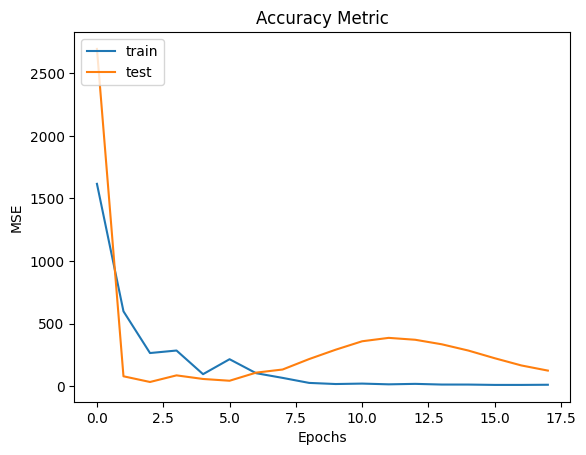

In [21]:
#gráfico avaliando a acurácia a partir de treino e teste
plt.plot(history.history['mean_squared_error'])
plt.plot(history.history['val_mean_squared_error'])
plt.title('Accuracy Metric')
plt.ylabel('MSE')
plt.xlabel('Epochs')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

3/3 [==============================] - 1s 318ms/step


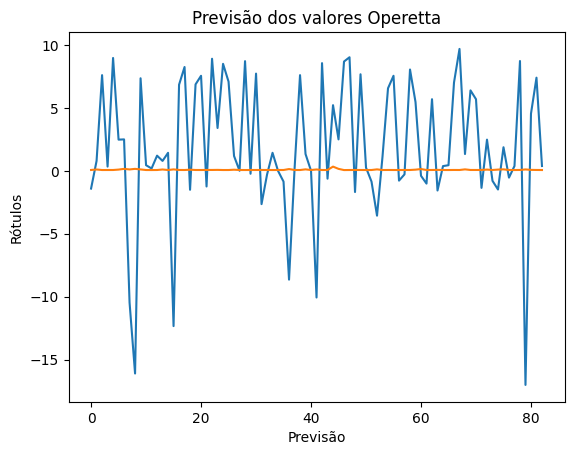

In [22]:
#avaliando a previsão do modelo com os rótulos
prev = modelo.predict(X_test)
plt.title('Previsão dos valores Operetta')
plt.ylabel('Rótulos')
plt.xlabel('Previsão')
plt.plot(prev)#azul - o que o modelo previu
plt.plot(y_test)#laranja - o que se sabe - observado
plt.show()

In [23]:
# Qualit model analisys
from sklearn.metrics import r2_score,mean_absolute_error, mean_squared_error, mean_squared_log_error, median_absolute_error

In [24]:
#buscando pelas métricas
print(f"{round(r2_score(y_test, prev) * 100, 2)}% r2_score") #raíz quadrada
print(f"{round(mean_absolute_error(y_test, prev), 2)} Erro médio absoluto")
print(f"{round(mean_squared_error(y_test, prev), 2)} Erro médio quadrático") #erro médio quadrático
# print(f"{round(median_absolute_error(y_test, prev), 2)}")#Erro médio absoluto sem %
#print(f"{round(median(y_test, prev), 2)} mediana") #erro médio quadrático

-2460865.64% r2_score
4.2 Erro médio absoluto
33.53 Erro médio quadrático


In [25]:
# Métricas do modelo de regressão
r2 = r2_score(y_test, prev)
mae = mean_absolute_error(y_test, prev)
mse = mean_squared_error(y_test, prev)
rmse = np.sqrt(mse)

print(f"{round(r2 * 100, 2)}% R² score")
print(f"{round(mae, 2)} Mean Absolute Error (MAE)")
print(f"{round(mse, 2)} Mean Squared Error (MSE)")
print(f"{round(rmse, 2)} Root Mean Squared Error (RMSE)")

-2460865.64% R² score
4.2 Mean Absolute Error (MAE)
33.53 Mean Squared Error (MSE)
5.79 Root Mean Squared Error (RMSE)


In [26]:
import numpy as np

def calculate_r_squared_manual(y_true, y_pred):
    """
    Calculates the coefficient of determination (R-squared) manually.

    Args:
        y_true (list or np.array): The true (observed) values.
        y_pred (list or np.array): The predicted values from the model.

    Returns:
        float: The R-squared value.
    """
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    # Calculate the mean of the true values
    y_true_mean = np.mean(y_true)

    # Calculate the Sum of Squares of Residuals (SS_res)
    ss_res = np.sum((y_true - y_pred) ** 2)

    # Calculate the Total Sum of Squares (SS_tot)
    ss_tot = np.sum((y_true - y_true_mean) ** 2)

    # Handle the case where SS_tot is zero (e.g., all y_true values are the same)
    if ss_tot == 0:
        return 1.0  # R-squared is 1 if there's no variance in y_true

    # Calculate R-squared
    r_squared = 1 - (ss_res / ss_tot)

    return r_squared

# === YOUR MODEL'S VALUES ===
# y_test = seus valores reais
# prev   = previsões geradas pelo modelo (modelo.predict)

r_squared_value = calculate_r_squared_manual(y_test, prev)
print(f"Manual R²: {r_squared_value}")


Manual R²: -2036217.1961829728


In [27]:
import numpy as np
print("Variância:", np.var(y_test))
print("Desvio Padrão:", np.std(y_test))
print("Amplitude:", np.ptp(y_test))


Variância: 0.0013624353059448393
Desvio Padrão: 0.03691118131332075
Amplitude: 0.274592


In [28]:
modelo.save(f'{diretorio}modelo_fluore_HUVEC_100_75_50_25_'+data+'.keras')